# Elevation and cycling

This notebook adds heights and grades to a walk graph, makes walking times depend on the slope, and builds a bike graph with its level of traffic stress. Heights normally come from a raster file (`add_elevation(graph, "dem.tif")`, which needs `pip install "iduedu[elevation]"`). So that the notebook runs anywhere, it uses a hill of 60 m defined as a function of the coordinates; Vasilyevsky Island itself is flat.

In [1]:
# To install IduEdu in a clean environment:
# !pip install IduEdu

OSM_ID = 1114252  # Vasilyevsky Island, Saint Petersburg

In [2]:
import numpy as np

import iduedu

walk = iduedu.get_walk_graph(osm_id=OSM_ID, clip_by_territory=True)
centre = walk.nodes_gdf.geometry.union_all().centroid


def hill(x, y):
    """A hill of 60 m with a radius of about 400 m in the middle of the island."""
    return 60 * np.exp(-((x - centre.x) ** 2 + (y - centre.y) ** 2) / (2 * 400**2))


walk = iduedu.add_elevation(walk, hill)
walk.edges_gdf[['length_meter', 'grade', 'grade_max', 'ascent', 'descent']].describe().round(3)

,length_meter,grade,grade_max,ascent,descent
count,29149.000,29149.000,29149.000,29149.000,29149.000
mean,24.902,0.000,0.006,0.087,0.075
std,35.079,0.016,0.016,0.526,0.418
min,0.150,-0.091,0.000,0.000,0.000
25%,6.979,-0.000,0.000,0.000,0.000
50%,14.550,0.000,0.000,0.000,0.000
75%,29.146,0.000,0.003,0.000,0.000
max,893.976,0.091,0.091,28.820,17.560


In [3]:
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
STREETS = "#d6d4ce"


def basemap(ax, graph, title):
    graph.edges_gdf.plot(ax=ax, color=STREETS, linewidth=0.4, zorder=1)
    ax.set_title(title)
    ax.set_axis_off()

`graph_stats` now reports heights and grades. `grade_mean` is the mean absolute grade weighted by length.

In [4]:
iduedu.graph_stats(walk)[['elevation_min', 'elevation_max', 'grade_mean', 'grade_max']].round(3)

elevation_min     0.000
elevation_max    59.940
grade_mean        0.006
grade_max         0.091
Name: value, dtype: float64

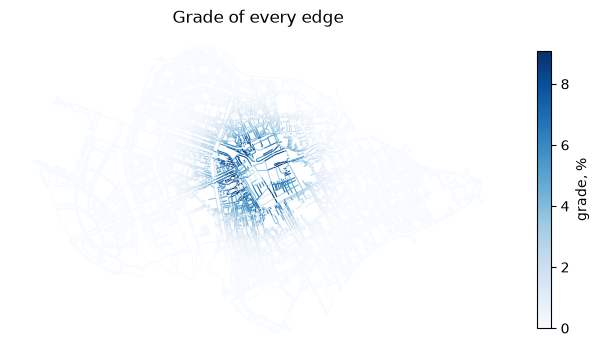

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
walk.edges_gdf.assign(percent=walk.edges_gdf['grade'].abs() * 100).plot(
    ax=ax, column='percent', cmap='Blues', legend=True, linewidth=0.8,
    legend_kwds={'label': 'grade, %', 'shrink': 0.6},
)
ax.set_title('Grade of every edge')
ax.set_axis_off()
plt.show()

## Walking times on slopes

`apply_grade_speed` divides the time of every edge by the relative speed of a model. Tobler's hiking function is fastest on a gentle descent of 5 %. The flat times stay in `time_min_flat`.

In [6]:
hilly = iduedu.apply_grade_speed(walk, 'tobler')

xs, ys = hilly.nodes_gdf.geometry.x, hilly.nodes_gdf.geometry.y
west = ((xs - (centre.x - 1500)) ** 2 + (ys - centre.y) ** 2).idxmin()
east = ((xs - (centre.x + 1500)) ** 2 + (ys - centre.y) ** 2).idxmin()

flat_cost, flat_route = iduedu.shortest_path(hilly, west, east, weight='time_min_flat')
hill_cost, hill_route = iduedu.shortest_path(hilly, west, east, weight='time_min')
print(f'flat ground: {flat_cost:.1f} min, with the hill: {hill_cost:.1f} min')

flat ground: 44.3 min, with the hill: 45.2 min


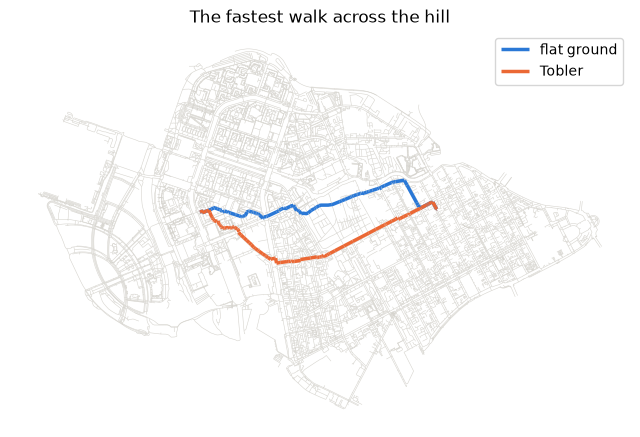

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
basemap(ax, hilly, 'The fastest walk across the hill')
hilly.path_to_edges(flat_route, weight='time_min_flat').plot(ax=ax, color=BLUE, linewidth=2.5, label='flat ground')
hilly.path_to_edges(hill_route, weight='time_min').plot(ax=ax, color=ORANGE, linewidth=2.5, label='Tobler')
ax.legend()
plt.show()

## A bike graph

`get_bike_graph` keeps every way a bicycle may use and gives each edge its cycling infrastructure (`cycle_infra`) and level of traffic stress (`lts`, 1 to 4). With `elevation` it also adds grades and the cycling speed model.

In [8]:
bike = iduedu.get_bike_graph(osm_id=OSM_ID, clip_by_territory=True, elevation=hill)
length = bike.edges_gdf.groupby(['cycle_infra', 'lts'])['length_meter'].sum() / 1000
length.round(1).rename('km').to_frame()

km
cycle_infra lts       
lane        3      3.8
mixed       1      3.2
            2    320.9
            3      2.3
            4     92.6
track       1     19.0

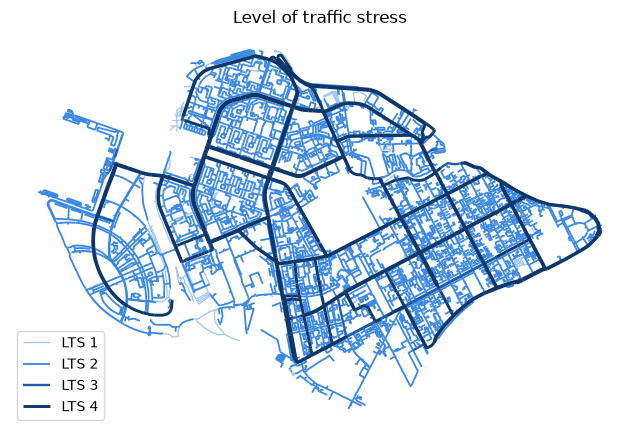

In [9]:
colours = {1: '#9ec5f4', 2: '#3987e5', 3: '#1c5cab', 4: '#0d366b'}
fig, ax = plt.subplots(figsize=(8, 6))
for level, colour in colours.items():
    bike.edges_gdf[bike.edges_gdf['lts'] == level].plot(ax=ax, color=colour, linewidth=0.5 + 0.4 * level,
                                                        label=f'LTS {level}')
ax.legend(loc='lower left')
ax.set_title('Level of traffic stress')
ax.set_axis_off()
plt.show()

`max_lts=2` keeps the network that most adults are willing to ride, and `keep_largest_subgraph` (the default) its largest strongly connected component: the part where every place can be reached from every other without riding in heavy traffic. Compare it with all the edges up to level 2.

In [10]:
low_stress = iduedu.get_bike_graph(osm_id=OSM_ID, clip_by_territory=True, max_lts=2)
pieces = iduedu.get_bike_graph(osm_id=OSM_ID, clip_by_territory=True, max_lts=2, keep_largest_subgraph=False)


def km(graph):
    return graph.edges_gdf['length_meter'].sum() / 1000


print(f'all ways: {km(bike):.0f} km, edges up to LTS 2: {km(pieces):.0f} km, '
      f'of them connected in both directions: {km(low_stress):.0f} km')

all ways: 442 km, edges up to LTS 2: 356 km, of them connected in both directions: 30 km


Most edges up to level 2 here are service roads inside the blocks. The streets between them are secondary and tertiary roads with `maxspeed=RU:urban`, which is not a number, so they take the default of 60 km/h for their class, the urban limit in Russia, and reach level 4. The low-stress edges therefore fall into many small pieces: even with the direction ignored, the largest piece holds 2 692 of the 13 644 nodes. Cycle lanes mapped on those streets would join them.

## Heights from a raster

With a digital elevation model the call is the same, and the raster may be in any CRS:

```python
walk = iduedu.add_elevation(walk, "dem.tif")
walk = iduedu.apply_grade_speed(walk, "tobler")
bike = iduedu.get_bike_graph(osm_id=OSM_ID, elevation="dem.tif")
```

Global models such as Copernicus GLO-30 measure roofs and trees in cities; use a terrain model for street grades. Spot heights and contour lines in a GeoDataFrame work as well (`column=` names the height column).

## Your own area

Replace `OSM_ID` with the id of an OSM boundary relation, or pass `territory=` a shapely polygon in EPSG:4326 or a
GeoDataFrame. Measures near the border of a graph are biased, because the network beyond it is missing: build the
graph for a larger area and pass the study area as `area=` to `graph_stats` and `centrality`. For many runs on one
region, read a local OSM file instead of Overpass with `iduedu.use_pbf(...)` (see the data sources page).